<a href="https://colab.research.google.com/github/VY-MS123/NTUC_Capstone_MarketAnalysis/blob/main/Capstone_Market.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
# Replace with your actual URL (ensure it's a direct link to the CSV file)
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'

df = pd.read_csv(url)

# Display the first few rows
df.head()

,customer_id,first_name,last_name,gender,age,country,income
0,CS00001,Isadora,Porto,Female,19,Brazil,117196
1,CS00002,Hugo,Carreño,Male,33,Chile,49256
2,CS00003,René,Olivera,Male,65,Mexico,33434
3,CS00004,Luiz Henrique,Pinto,Male,55,Brazil,75302
4,CS00005,Leonardo,Monteiro,Male,19,Brazil,32280


In [ ]:
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

df = pd.read_csv(url)

df.head()

,order_id,customer_id,product_name,description,price,discount,tax,order_date,quantity,shipping_cost,shipping_date
0,ODSHP00001,CS00001,Furniture,Transform your space with this stylish and fun...,645.52,0.37,0.02,26-05-2020,9,8.91,29-05-2020
1,ODSHP00002,CS00002,Dress,Look and feel your best with this elegant dress.,28.90,0.05,0.02,29-12-2022,9,13.95,29-12-2022
2,ODSHP00003,CS00003,Furniture,Transform your space with this stylish and fun...,3536.49,0.21,0.04,06-03-2021,3,36.42,06-03-2021
3,ODSHP00004,CS00004,Shoes,Step out in style with these fashionable shoes.,97.80,0.11,0.08,11-03-2020,7,9.35,13-03-2020
4,ODSHP00005,CS00005,Rugs,Add warmth and texture to your floors with the...,1785.38,0.13,0.00,12-03-2022,7,8.55,15-03-2022


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       50000 non-null  object 
 1   customer_id    50000 non-null  object 
 2   product_name   50000 non-null  object 
 3   description    50000 non-null  object 
 4   price          50000 non-null  float64
 5   discount       50000 non-null  float64
 6   tax            50000 non-null  float64
 7   order_date     50000 non-null  object 
 8   quantity       50000 non-null  int64  
 9   shipping_cost  50000 non-null  float64
 10  shipping_date  50000 non-null  object 
dtypes: float64(4), int64(1), object(6)
memory usage: 4.2+ MB


In [ ]:
df.isnull().sum()


,0
order_id,0
customer_id,0
product_name,0
description,0
price,0
discount,0
tax,0
order_date,0
quantity,0
shipping_cost,0


In [ ]:
#change the Data type
columns_to_convert = ['order_id', 'customer_id', 'product_name']
df[columns_to_convert] = df[columns_to_convert].astype('string')

In [ ]:
columns_to_convert = ['description']
df[columns_to_convert] = df[columns_to_convert].astype('string')

In [ ]:
columns_to_convert = ['order_date', 'shipping_date']
for col in columns_to_convert:
    df[col] = pd.to_datetime(df[col], format='%d-%m-%Y')

In [ ]:
#recheck data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       50000 non-null  string        
 1   customer_id    50000 non-null  string        
 2   product_name   50000 non-null  string        
 3   description    50000 non-null  string        
 4   price          50000 non-null  float64       
 5   discount       50000 non-null  float64       
 6   tax            50000 non-null  float64       
 7   order_date     50000 non-null  datetime64[ns]
 8   quantity       50000 non-null  int64         
 9   shipping_cost  50000 non-null  float64       
 10  shipping_date  50000 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(4), int64(1), string(4)
memory usage: 4.2 MB


In [ ]:
total_revenue = df["price"].sum()
total_orders = df["quantity"].sum()
avg_order_value = df["price"].mean()

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Units Sold: {total_orders:,}")
print(f"Average Sales Value per Item: ${avg_order_value:,.2f}")

Total Revenue: $63,796,343.63
Total Units Sold: 274,878
Average Sales Value per Item: $1,275.93


Objective 1
Regional Sales Performance & Grographic Market Analysis:
Evaluate Total Revenue transaction volume

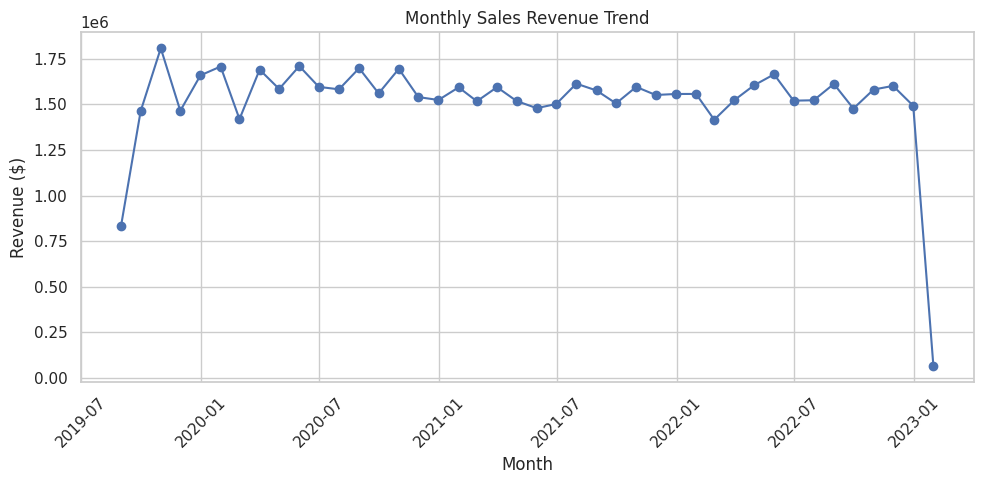

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the URL and parse order_date as datetime directly
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df = pd.read_csv(url, parse_dates=['order_date'], dayfirst=True)

# Calculate TotalSales as simply the sum of the price column per user context
df["TotalSales"] = df["price"]

# Group by month using TotalSales (which is equal to price)
monthly_sales = df.resample("ME", on="order_date")["TotalSales"].sum().reset_index()

# Plot Monthly Trend with correct Revenue definition
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales["order_date"],
    monthly_sales["TotalSales"],
    marker="o",
    color="b",
    linestyle="-",
)
plt.title("Monthly Sales Revenue Trend (Sum of Prices)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Sales Trend**
The highest sales result occurred in 2019, with approximately 1.75 million.

The sales drop significantly in year 2023 should not be interpreted as genuine seasonal declines because those are incomplete months as sales up to 16 Jan 2023 being taken up for this analysis.

Finding: Monthly revenue is otherwise relatively stable, generally falling between approximately 1.6 million and 1.5 million. Seasonal conclusions should be calculated using complete months only.

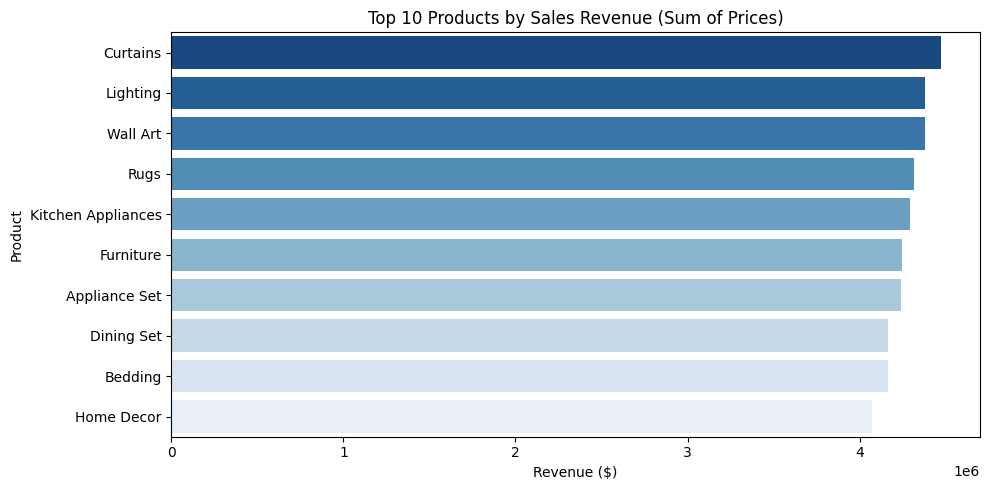

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate TotalSales as simply the sum of prices
df["TotalSales"] = df['price']

# Top 10 products by revenue (sum of prices)
top_products = (
    df.groupby("product_name")["TotalSales"].sum().nlargest(10).reset_index()
)

# Plot Top Products
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_products,
    x="TotalSales",
    y="product_name",
    hue="product_name",
    palette="Blues_r",
    legend=False
)
plt.title("Top 10 Products by Sales Revenue (Sum of Prices)")
plt.xlabel("Revenue ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

The highest margin product category is 'Curtains' with a total calculated profit of $4,427,800.04.



,product_name,Profit
4,Curtains,"$4,427,800.04"
16,Lighting,"$4,335,555.68"
28,Wall Art,"$4,332,059.01"
17,Rugs,"$4,268,003.32"
14,Kitchen Appliances,"$4,244,198.50"
8,Furniture,"$4,200,475.55"
1,Appliance Set,"$4,192,642.95"
5,Dining Set,"$4,121,323.50"
2,Bedding,"$4,118,146.27"
11,Home Decor,"$4,027,289.17"


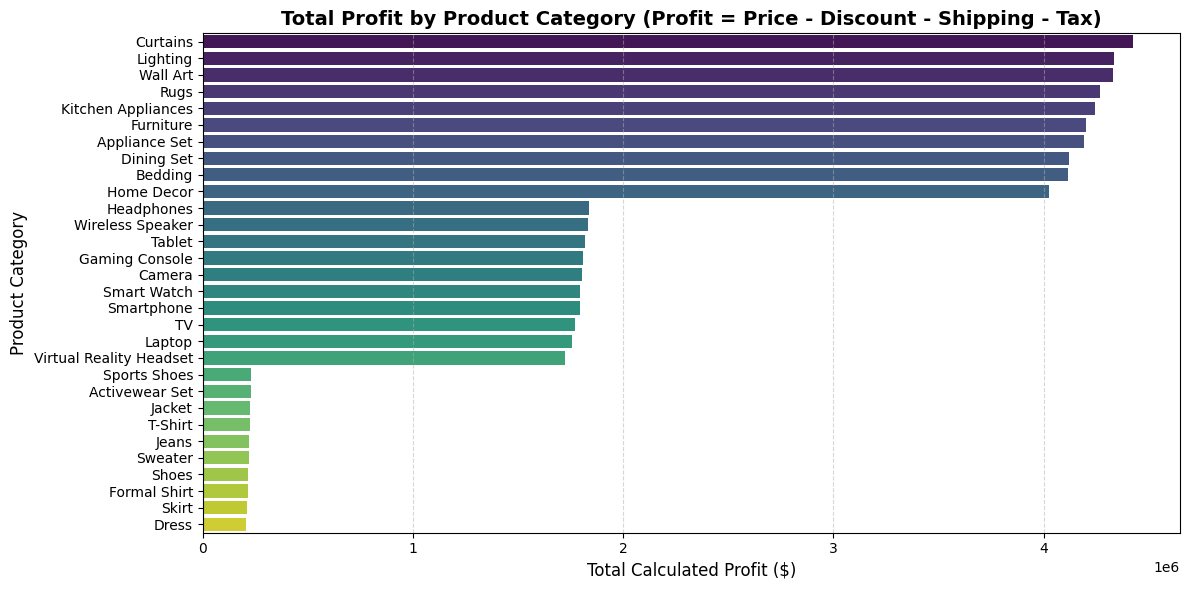

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the purchase dataset
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df_purch = pd.read_csv(purch_url)

# 2. Calculate profit using the user's formula
# profit = price - discount - shipping cost - tax
df_purch['Profit'] = df_purch['price'] - df_purch['discount'] - df_purch['shipping_cost'] - df_purch['tax']

# 3. Aggregate total profit by product
product_margins = df_purch.groupby('product_name')['Profit'].sum().reset_index()
product_margins = product_margins.sort_values(by='Profit', ascending=False)

# 4. Identify the highest margin product
highest_margin_product = product_margins.iloc[0]
print(f"The highest margin product category is '{highest_margin_product['product_name']}' with a total calculated profit of ${highest_margin_product['Profit']:,.2f}.\n")

# Display the top products by profit
display(product_margins.style.format({'Profit': '${:,.2f}'}))

# 5. Visualize the product profits
plt.figure(figsize=(12, 6))
sns.barplot(
    data=product_margins,
    x='Profit',
    y='product_name',
    palette='viridis',
    hue='product_name',
    legend=False
)
plt.title('Total Profit by Product Category (Profit = Price - Discount - Shipping - Tax)', fontsize=14, fontweight='bold')
plt.xlabel('Total Calculated Profit ($)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Sales Trend By Products**
Based on the graph above, Curtains ($4.48M), Lighting ($4.38M), Wall Art ($4.38M), Rugs ($4.31M) and Kitchen Appliances ($4.29M) are the major contributors for total revenue, which representing 34.23% of total revenue.

In [ ]:
import pandas as pd

# 1. Load the customer and purchase datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# 2. Calculate spending for each purchase record (sales = price)
purch_df['TotalSpending'] = purch_df['price']

# 3. Aggregate spending by customer_id
customer_spending = purch_df.groupby('customer_id')['TotalSpending'].sum().reset_index()

# 4. Merge with customer details to get name and demographic information
top_spenders = pd.merge(customer_spending, cust_df, on='customer_id')

# 5. Sort by TotalSpending in descending order and select the top 10
top_10_spenders = top_spenders.sort_values(by='TotalSpending', ascending=False).head(10)

# Display results
display(top_10_spenders[['customer_id', 'first_name', 'last_name', 'country', 'TotalSpending']])

,customer_id,first_name,last_name,country,TotalSpending
608,CS00609,Martín,de la Torre,Mexico,90616.95
170,CS00171,André,da Cruz,Brazil,89808.94
833,CS00834,Edith,Ortega,Colombia,89101.10
383,CS00384,Ariel,Contreras,Chile,88677.07
321,CS00322,Pedro,Silva,Brazil,87651.70
335,CS00336,Alberto,Alfonso,Colombia,87482.50
444,CS00445,Julio César,Nieves,Mexico,85754.16
350,CS00351,Omar,Quintero,Colombia,85351.37
941,CS00942,Leidy,Guerrero,Colombia,84804.35
87,CS00088,Bárbara,Rodríguez,Chile,84476.94


**Sales Trend By Customers**
The table represents the Top 10 customers ranked by Total Spending, indicating the most valuable customers based on cumulative purchase value.

Based on the analysis, there is no significant customer concentration risk, as spending levels among the top customers are relatively similar and no single customer contributes a disproportionately large share of total revenue.

Top 5 Countries by Total Revenue (Sum of Prices):


,country,TotalRevenue
2,Colombia,"$18,005,623.56"
1,Chile,"$16,166,076.12"
3,Mexico,"$14,898,656.78"
0,Brazil,"$14,725,987.17"


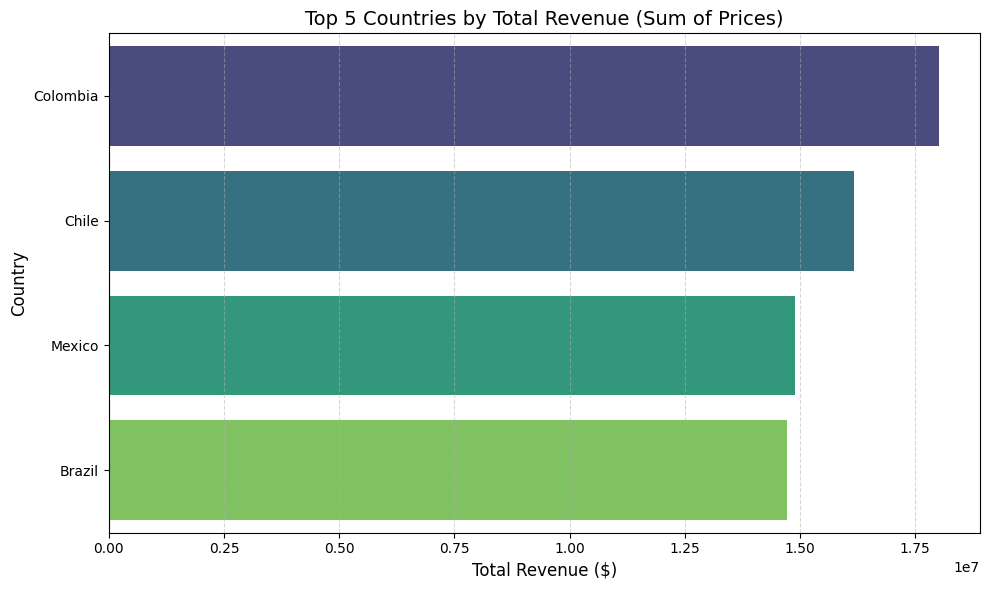

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we use purchase and customer datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# Calculate revenue based on price alone (sales = price)
purch_df['TotalRevenue'] = purch_df['price']

# Merge datasets on customer_id to get customer geographic info
merged_df = pd.merge(purch_df, cust_df, on='customer_id')

# Aggregate total revenue by country
country_revenue = merged_df.groupby('country')['TotalRevenue'].sum().reset_index()

# Select the top 5 countries by revenue
top_5_countries = country_revenue.sort_values(by='TotalRevenue', ascending=False).head(5)

# Display the tabular summary
print("Top 5 Countries by Total Revenue (Sum of Prices):")
display(top_5_countries.style.format({'TotalRevenue': '${:,.2f}'}))

# Visualize the results
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_5_countries,
    x='TotalRevenue',
    y='country',
    hue='country',
    palette='viridis',
    legend=False
)
plt.title('Top 5 Countries by Total Revenue (Sum of Prices)', fontsize=14)
plt.xlabel('Total Revenue ($)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Revenue Analysis by Country**

The chart presents the total revenue generated by customers from each country, providing insights into the company's strongest and weakest markets.

The analysis shows that Colombia is the leading revenue-generating market, followed by Chile, Mexico, and Brazil. While Colombia demonstrates the strongest overall performance, all four countries contribute significantly to total sales revenue. The relatively balanced distribution of revenue across countries indicates a diversified customer portfolio and reduces geographic concentration risk. To maximise future growth, the company should continue strengthening its position in Colombia while exploring strategies to improve customer spending and market penetration in Brazil.

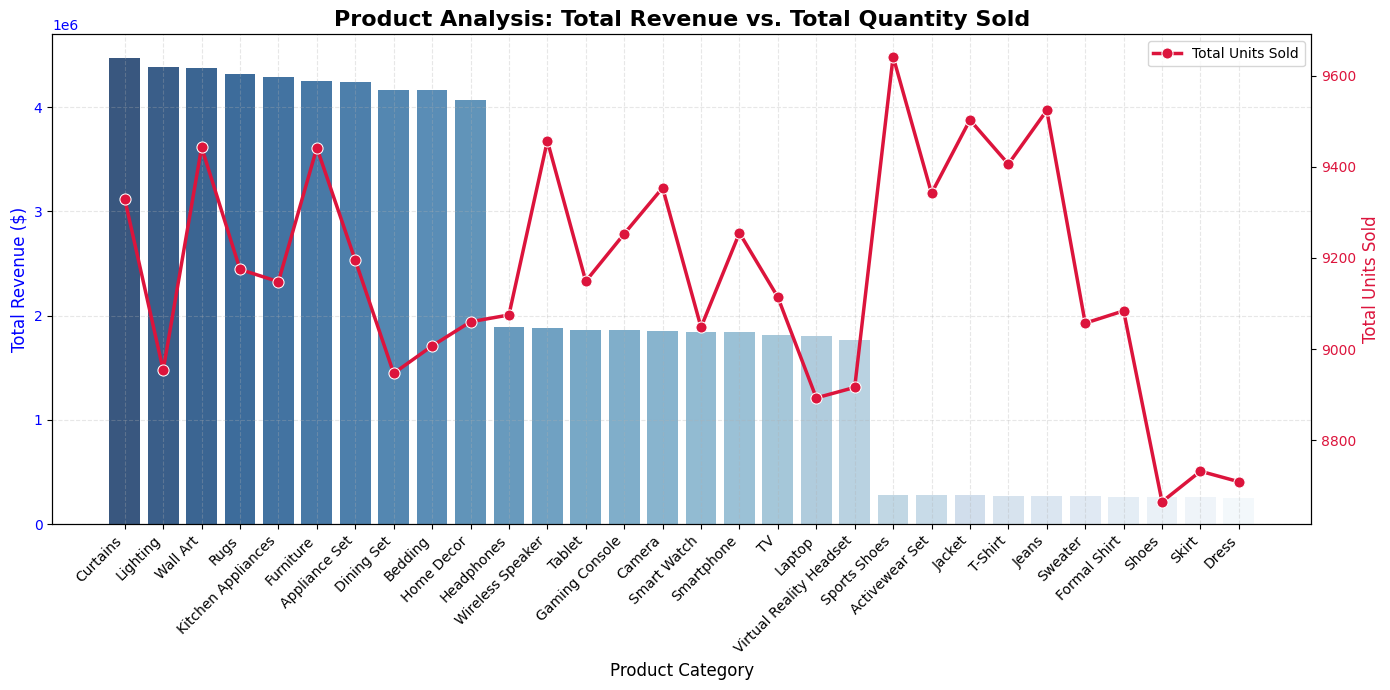

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df_purch = pd.read_csv(purch_url)

# 2. Aggregate both revenue (price) and quantity (units sold) by product
product_stats = df_purch.groupby('product_name').agg(
    TotalRevenue=('price', 'sum'),
    TotalQuantity=('quantity', 'sum')
).reset_index()

# Sort by Revenue for clean visualization flow
product_stats = product_stats.sort_values(by='TotalRevenue', ascending=False)

# 3. Create a dual-axis plot
fig, ax1 = plt.subplots(figsize=(14, 7))

# Primary axis: Bar chart for Total Revenue
sns.barplot(
    data=product_stats,
    x='product_name',
    y='TotalRevenue',
    ax=ax1,
    palette='Blues_r',
    hue='product_name',
    legend=False,
    alpha=0.85
)
ax1.set_title('Product Analysis: Total Revenue vs. Total Quantity Sold', fontsize=16, fontweight='bold')
ax1.set_xlabel('Product Category', fontsize=12)
ax1.set_ylabel('Total Revenue ($)', color='b', fontsize=12)
ax1.tick_params(axis='y', labelcolor='b')

# Set correct tick locations first to prevent warnings
ax1.set_xticks(range(len(product_stats)))
ax1.set_xticklabels(product_stats['product_name'], rotation=45, ha='right')

# Secondary axis: Line chart with markers for Quantity Sold
ax2 = ax1.twinx()
sns.lineplot(
    data=product_stats,
    x='product_name',
    y='TotalQuantity',
    ax=ax2,
    color='crimson',
    marker='o',
    linewidth=2.5,
    markersize=8,
    sort=False,
    label='Total Units Sold'
)
ax2.set_ylabel('Total Units Sold', color='crimson', fontsize=12)
ax2.tick_params(axis='y', labelcolor='crimson')
ax2.legend(loc='upper right')

ax1.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Product Analysis: Total Revenue vs. Total Quantity Sold

This chart compares total revenue (blue bars) and total units sold (red line) across different product categories. The analysis helps identify whether revenue is driven by high sales volume, high product value, or a combination of both.

The analysis reveals that home furnishing and décor products are the company's primary revenue drivers, with Curtains, Lighting, and Wall Art generating the highest sales revenue. In contrast, fashion products such as Sports Shoes, Jeans, and Jackets achieve the highest sales volumes but contribute significantly less revenue per unit sold. This indicates two distinct business strategies within the product portfolio: premium products drive revenue, while fashion products drive demand and customer traffic. To maximise profitability, management should focus on expanding high-revenue home-related products while leveraging high-volume fashion categories for cross-selling and customer engagement opportunities.

Objective 2: Impact of Discount Strategies on Quantity Purchased and Total Sales

The visualisation evaluates whether higher discounts encourage customers to purchase more products and whether discounting contributes positively to overall sales performance.

Correlation between Discount and Quantity Purchased: -0.0010
Correlation between Discount and Total Sales Revenue: 0.0009

Summary Statistics by Discount Tier:


,Average_Quantity,Average_Sales,Order_Count
Discount_Tier,,,
0% (No Discount),5.721174,1335.104235,477
1% - 15% (Low),5.496724,1280.843208,15111
16% - 30% (Medium),5.499165,1267.137617,14979
31%+ (High),5.491484,1277.426174,19433


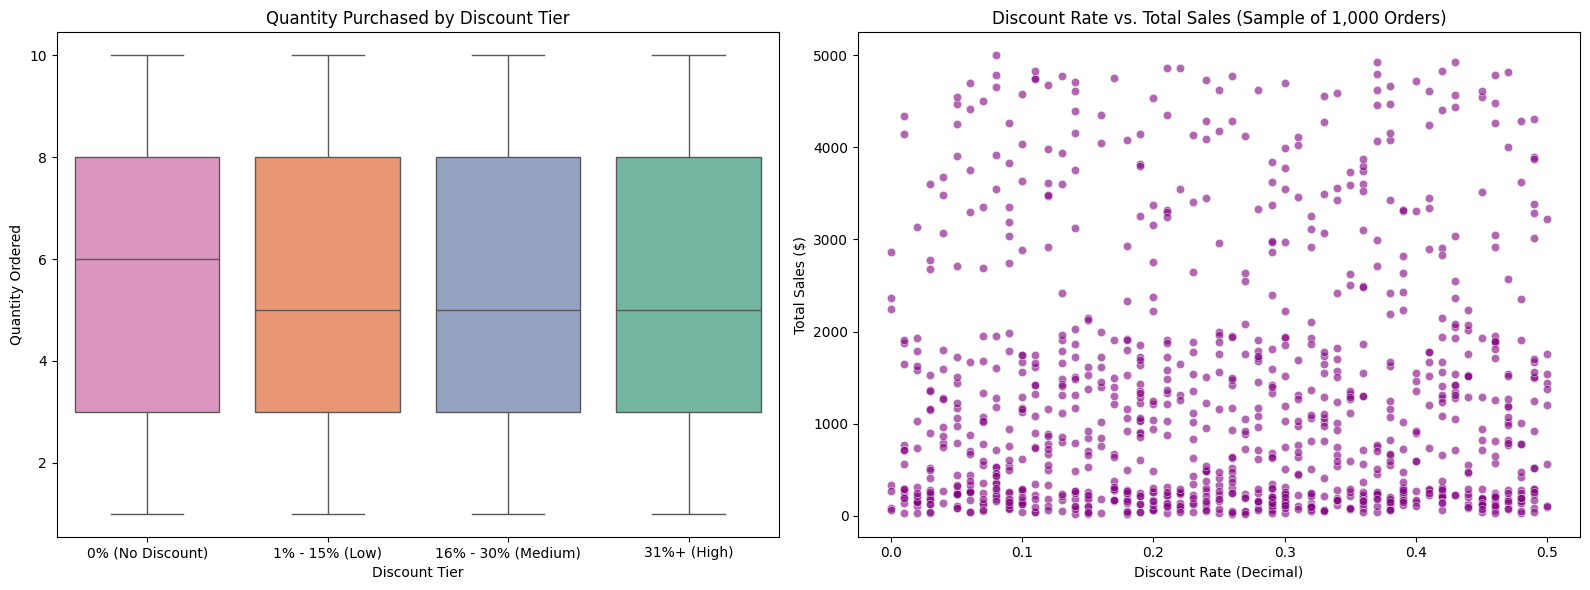

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we are using the primary purchase dataframe
# Under user definition: total sales = price
df['TotalSales'] = df['price']

# 1. Calculate Correlation
corr_qty = df['discount'].corr(df['quantity'])
corr_sales = df['discount'].corr(df['TotalSales'])
print(f"Correlation between Discount and Quantity Purchased: {corr_qty:.4f}")
print(f"Correlation between Discount and Total Sales Revenue: {corr_sales:.4f}")

# 2. Bin discounts to see categorical impact
def bin_discount(discount):
    if discount == 0:
        return '0% (No Discount)'
    elif discount <= 0.15:
        return '1% - 15% (Low)'
    elif discount <= 0.30:
        return '16% - 30% (Medium)'
    else:
        return '31%+ (High)'

df['Discount_Tier'] = df['discount'].apply(bin_discount)
discount_grouped = df.groupby('Discount_Tier').agg(
    Average_Quantity=('quantity', 'mean'),
    Average_Sales=('TotalSales', 'mean'),
    Order_Count=('order_id', 'count')
).reindex(['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'])

print("\nSummary Statistics by Discount Tier:")
display(discount_grouped)

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Discount vs Quantity (Boxplot over Tiers)
sns.boxplot(
    data=df,
    x='Discount_Tier',
    y='quantity',
    ax=axes[0],
    order=['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'],
    palette='Set2',
    hue='Discount_Tier',
    legend=False
)
axes[0].set_title('Quantity Purchased by Discount Tier')
axes[0].set_xlabel('Discount Tier')
axes[0].set_ylabel('Quantity Ordered')

# Plot 2: Scatter plot of Discount vs Total Sales (which equals price) to check overall distribution
sns.scatterplot(
    data=df.sample(1000, random_state=42),  # sample to avoid overplotting
    x='discount',
    y='TotalSales',
    ax=axes[1],
    alpha=0.6,
    color='purple'
)
axes[1].set_title('Discount Rate vs. Total Sales (Sample of 1,000 Orders)')
axes[1].set_xlabel('Discount Rate (Decimal)')
axes[1].set_ylabel('Total Sales ($)')

plt.tight_layout()
plt.show()

**Impact of Discount Strategies on Sales Performance**

The box plot shows that the quantity purchased remains relatively consistent across all discount tiers. The median order quantity ranges between 5 and 6 units, and the distribution of purchases is very similar regardless of whether customers receive no discount or a discount above 31%. This suggests that higher discounts do not significantly encourage customers to buy more items, as purchasing behaviour remains stable across all discount levels.

The scatter plot further supports this observation by showing no clear relationship between discount rate and total sales value. High-value and low-value transactions occur across the entire discount range, indicating that larger discounts do not consistently generate higher sales. Customers continue to make both small and large purchases regardless of the discount offered.

Overall, the findings suggest that discounts have a limited impact on increasing customer demand. While discounts reduce selling prices, they do not appear to meaningfully increase purchase quantities or sales value. Therefore, the company should consider using more targeted promotions, loyalty programmes, or product-specific campaigns rather than relying heavily on broad discounting strategies to drive revenue growth.

Objective 3:
Product Demand and Revenue Concentration Analysis

 Identify which specific Product lines dominate total revenue generation and sales volume to pinpoint core revenue drivers versus low-performing inventory

--- PRODUCT REVENUE CONCENTRATION ---
Top 5 product lines generate 34.24% of total sales.

--- CUSTOMER REVENUE CONCENTRATION ---
Top 10 highest-spending customers generate 1.37% of total sales.
Top 20% of customers generate 24.09% of total sales.


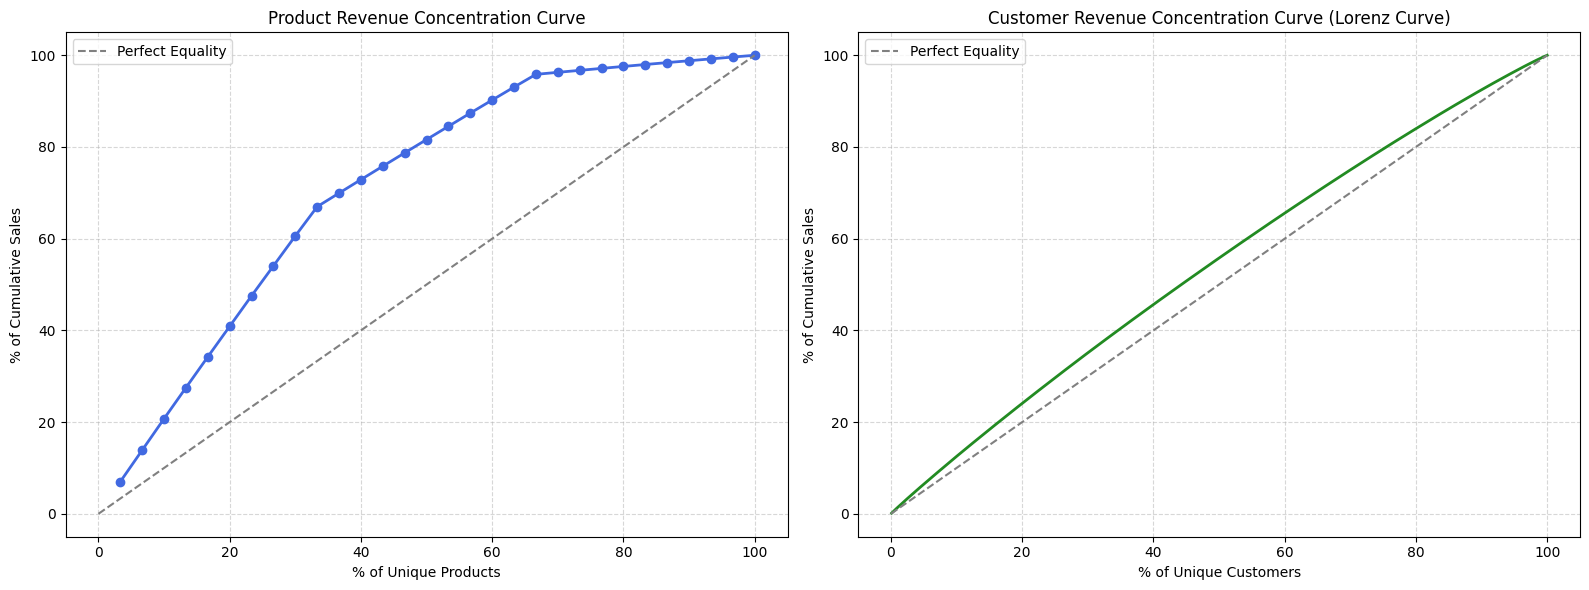

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load fresh data
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df_purch = pd.read_csv(purch_url)

# Force rule: sales = price
df_purch['Sales'] = df_purch['price']

# --- 1. Product Revenue Concentration ---
product_sales = df_purch.groupby('product_name')['Sales'].sum().sort_values(ascending=False).reset_index()
product_sales['Cum_Sales'] = product_sales['Sales'].cumsum()
product_sales['Cum_Percentage'] = (product_sales['Cum_Sales'] / product_sales['Sales'].sum()) * 100
product_sales['Product_Count_Pct'] = (np.arange(1, len(product_sales) + 1) / len(product_sales)) * 100

# --- 2. Customer Revenue Concentration ---
customer_sales = df_purch.groupby('customer_id')['Sales'].sum().sort_values(ascending=False).reset_index()
customer_sales['Cum_Sales'] = customer_sales['Sales'].cumsum()
customer_sales['Cum_Percentage'] = (customer_sales['Cum_Sales'] / customer_sales['Sales'].sum()) * 100
customer_sales['Customer_Count_Pct'] = (np.arange(1, len(customer_sales) + 1) / len(customer_sales)) * 100

# Print concentration benchmarks
print("--- PRODUCT REVENUE CONCENTRATION ---")
top_5_prod_pct = product_sales.iloc[4]['Cum_Percentage'] if len(product_sales) >= 5 else 100
print(f"Top 5 product lines generate {top_5_prod_pct:.2f}% of total sales.")

print("\n--- CUSTOMER REVENUE CONCENTRATION ---")
top_10_cust_pct = customer_sales.iloc[9]['Cum_Percentage'] if len(customer_sales) >= 10 else 100
top_20_percent_cust = customer_sales[customer_sales['Customer_Count_Pct'] <= 20].iloc[-1]['Cum_Percentage']
print(f"Top 10 highest-spending customers generate {top_10_cust_pct:.2f}% of total sales.")
print(f"Top 20% of customers generate {top_20_percent_cust:.2f}% of total sales.")

# --- 3. Plot Lorenz / Concentration Curves ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Product Concentration Plot
axes[0].plot(product_sales['Product_Count_Pct'], product_sales['Cum_Percentage'], marker='o', color='royalblue', linewidth=2)
axes[0].plot([0, 100], [0, 100], linestyle='--', color='gray', label='Perfect Equality')
axes[0].set_title('Product Revenue Concentration Curve')
axes[0].set_xlabel('% of Unique Products')
axes[0].set_ylabel('% of Cumulative Sales')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Customer Concentration Plot
axes[1].plot(customer_sales['Customer_Count_Pct'], customer_sales['Cum_Percentage'], color='forestgreen', linewidth=2)
axes[1].plot([0, 100], [0, 100], linestyle='--', color='gray', label='Perfect Equality')
axes[1].set_title('Customer Revenue Concentration Curve (Lorenz Curve)')
axes[1].set_xlabel('% of Unique Customers')
axes[1].set_ylabel('% of Cumulative Sales')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

**Product Revenue Concentration**

The top 5 product categories (Curtains, Lighting, Wall Art, Rugs, and Kitchen Appliances) account for 34.24% of your total sales.

This suggests a very balanced product revenue distribution. Rather than relying heavily on one single flagship product line, sales are spread relatively evenly across your catalog, mitigating the risk of product obsolescence or supply chain disruption for any individual category.

**Customer Revenue Concentration (Lorenz Curve)**

 - The top 10 highest-spending customers contribute only 1.37% of cumulative sales revenue.
 - The top 20% of your customer base accounts for only 24.09% of cumulative sales revenue.

This confirms exceptionally low customer concentration risk. The Lorenz curve for customer revenue sits very close to the line of perfect equality (perfectly linear cumulative contribution). Your business does not depend on a few high-value "whales"; instead, revenue is highly democratized across a very broad and diversified customer base.



--- BOTTOM 10 PRODUCTS BY TOTAL REVENUE (UNDERPERFORMERS) ---


,product_name,Total_Revenue,Units_Sold,Average_Price
6,Dress,"$248,819.60","8,709",$157.68
19,Skirt,"$255,799.34","8,732",$159.67
18,Shoes,"$257,841.80","8,665",$162.37
7,Formal Shirt,"$257,860.47","9,084",$157.33
23,Sweater,"$266,695.47","9,057",$160.27
13,Jeans,"$267,658.51","9,524",$158.19
24,T-Shirt,"$271,671.59","9,406",$158.41
12,Jacket,"$274,121.08","9,503",$162.59
0,Activewear Set,"$274,542.28","9,342",$160.83
22,Sports Shoes,"$280,939.34","9,642",$159.35


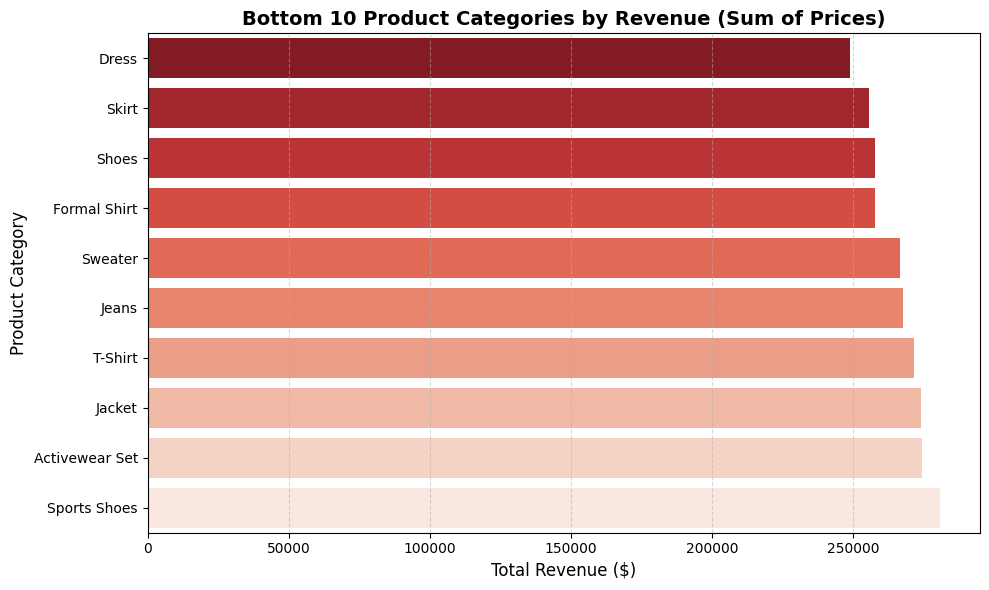

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df_purch = pd.read_csv(purch_url)

# Ensure user rule: sales = price
df_purch['Sales'] = df_purch['price']

# 2. Aggregate sales per product
product_summary = df_purch.groupby('product_name').agg(
    Total_Revenue=('Sales', 'sum'),
    Units_Sold=('quantity', 'sum'),
    Average_Price=('price', 'mean')
).reset_index().sort_values(by='Total_Revenue', ascending=True)

# Let's flag bottom 10 products contributing the least to revenue
bottom_10_products = product_summary.head(10)

print("--- BOTTOM 10 PRODUCTS BY TOTAL REVENUE (UNDERPERFORMERS) ---")
display(bottom_10_products.style.format({
    'Total_Revenue': '${:,.2f}',
    'Units_Sold': '{:,}',
    'Average_Price': '${:,.2f}'
}))

# 3. Visualize underperforming products
plt.figure(figsize=(10, 6))
sns.barplot(
    data=bottom_10_products,
    x='Total_Revenue',
    y='product_name',
    palette='Reds_r',
    hue='product_name',
    legend=False
)
plt.title('Bottom 10 Product Categories by Revenue (Sum of Prices)', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue ($)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Underperforming Product Categories Analysis**

The chart highlights the Bottom 10 Product Categories by Revenue, representing the lowest-performing products based on total sales revenue.

The lowest-performing category is Dress, generating approximately $250,000 in revenue. This is followed by Skirt, Shoes, Formal Shirt, Sweater, Jeans, T-Shirt, Jacket, Activewear Set, and Sports Shoes, with revenues ranging between approximately $250,000 and $285,000.

However, product categories such as Sports Shoes, Activewear Sets, Jackets, and T-Shirts recorded relatively high sales volumes yet remain among the lowest revenue contributors. This suggests that these products are sold at lower average selling prices, resulting in lower revenue generation despite strong demand. If these products are intentionally positioned as traffic-driving items to enhance brand awareness and customer engagement through frequent transactions, the strategy may be justified. Otherwise, management should carefully evaluate the profitability of these categories, as focusing on highly price-competitive products with low margins may not support long-term revenue and profit growth.


Objective 4:
Evaluate Customer Value and Profitability

Identify high-value, medium-value, and low value customers by analysing revenue contribution and customer lifetime value, helping the company focus retention efforts on profitable customers.

--- CUSTOMER SEGMENTATION SUMMARY ---


,Customer_Segment,Avg_Total_Sales,Avg_Total_Profit,Avg_Orders,Total_Segment_Revenue,Customer_Count,Profit_Margin_Percent
0,Low-Value Customer,"$53,798.40","$38,994.72",50.0,"$17,968,663.98",334,72.48%
1,Medium-Value Customer,"$63,598.92","$46,407.22",50.0,"$21,114,840.02",332,72.97%
2,High-Value Customer,"$73,990.54","$54,163.12",50.0,"$24,712,839.63",334,73.20%


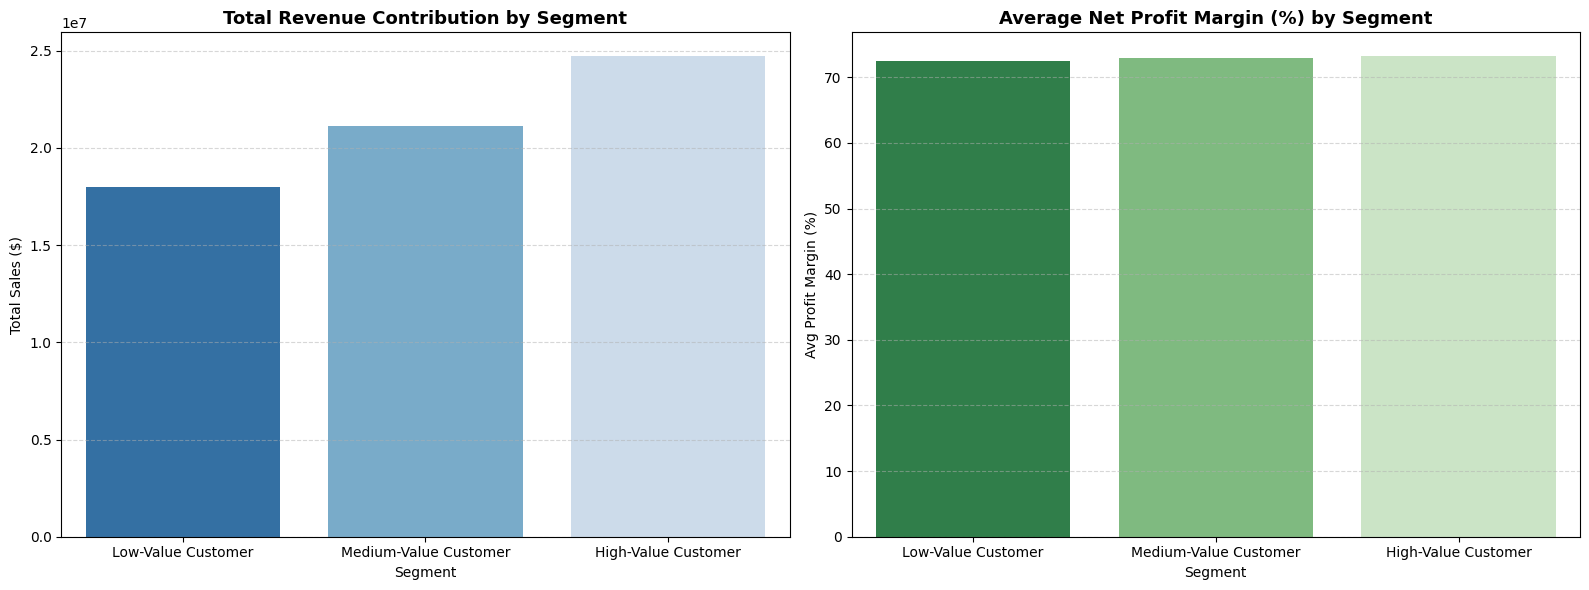

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load the customer and purchase datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# 2. Financial Calculations (sales = price)
purch_df['Net_Revenue'] = purch_df['price'] * (1 - purch_df['discount'])
purch_df['Estimated_Profit'] = purch_df['Net_Revenue'] - purch_df['shipping_cost'] + purch_df['tax']

# Aggregate at Customer level
customer_financials = purch_df.groupby('customer_id').agg(
    Total_Sales=('price', 'sum'),
    Total_Net_Revenue=('Net_Revenue', 'sum'),
    Total_Profit=('Estimated_Profit', 'sum'),
    Order_Count=('order_id', 'count')
).reset_index()

# 3. Customer Value Segmentation based on Total_Sales (CLV)
# We will segment customers based on 3-tier quantiles
segment_labels = ['Low-Value Customer', 'Medium-Value Customer', 'High-Value Customer']
customer_financials['Customer_Segment'] = pd.qcut(
    customer_financials['Total_Sales'],
    q=3,
    labels=segment_labels
)

# Calculate segment average metrics with observed=False to fix the FutureWarning
segment_summary = customer_financials.groupby('Customer_Segment', observed=False).agg(
    Avg_Total_Sales=('Total_Sales', 'mean'),
    Avg_Total_Profit=('Total_Profit', 'mean'),
    Avg_Orders=('Order_Count', 'mean'),
    Total_Segment_Revenue=('Total_Sales', 'sum'),
    Customer_Count=('customer_id', 'count')
).reset_index()

# Calculate segment profit margin %
segment_summary['Profit_Margin_Percent'] = (segment_summary['Avg_Total_Profit'] / segment_summary['Avg_Total_Sales']) * 100

print("--- CUSTOMER SEGMENTATION SUMMARY ---")
display(segment_summary.style.format({
    'Avg_Total_Sales': '${:,.2f}',
    'Avg_Total_Profit': '${:,.2f}',
    'Avg_Orders': '{:.1f}',
    'Total_Segment_Revenue': '${:,.2f}',
    'Customer_Count': '{:,}',
    'Profit_Margin_Percent': '{:.2f}%'
}))

# 4. Profitability Visualization per Segment
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Total Revenue contribution by Segment
sns.barplot(
    data=segment_summary,
    x='Customer_Segment',
    y='Total_Segment_Revenue',
    ax=axes[0],
    palette='Blues_r',
    hue='Customer_Segment',
    legend=False
)
axes[0].set_title('Total Revenue Contribution by Segment', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Total Sales ($)')
axes[0].grid(True, axis='y', linestyle='--', alpha=0.5)

# Plot 2: Average Profit Margin per Segment
sns.barplot(
    data=segment_summary,
    x='Customer_Segment',
    y='Profit_Margin_Percent',
    ax=axes[1],
    palette='Greens_r',
    hue='Customer_Segment',
    legend=False
)
axes[1].set_title('Average Net Profit Margin (%) by Segment', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Segment')
axes[1].set_ylabel('Avg Profit Margin (%)')
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Customer Value and Profitability Analysis**

The chart shows that High-Value Customers contribute the largest share of revenue, generating approximately $24.7 million, followed by Medium-Value Customers at approximately $21.1 million and Low-Value Customers at approximately $18.0 million. This indicates that customers classified as high-value are a key driver of business performance, as they contribute significantly more sales than other customer segments. The results suggest that retaining these customers and increasing their loyalty can have a substantial impact on overall revenue growth.

The average net profit margin is relatively consistent across all customer segments, ranging from approximately 72% to 74%. This means the company earns a similar profit percentage regardless of customer type. Therefore, the higher profitability generated by high-value customers is mainly due to their greater spending rather than higher margins. As a result, the company should focus on retaining high-value customers and developing strategies to move medium-value customers into the high-value segment through targeted marketing, cross-selling, and loyalty programmes, as increased customer spending is likely to directly improve both revenue and profit.

--- CUSTOMER COUNT BY AGE GROUP AND VALUE SEGMENT ---


Customer_Segment,Low-Value Customer,Medium-Value Customer,High-Value Customer
Age_Group,,,
Below 18,0,0,0
20 - 30,93,87,87
30 - 40,86,65,62
40 - 50,70,63,75
50 - 60,55,86,75
>60,30,31,35


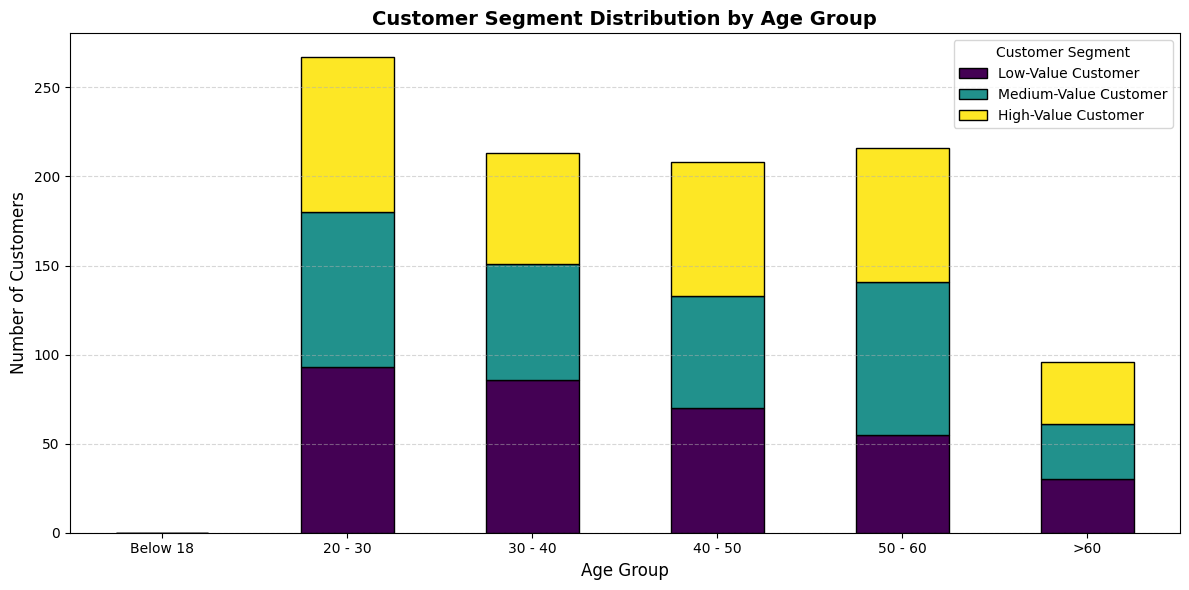

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load the customer and purchase datasets to guarantee variables exist
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# 2. Compute customer financial segmentation metrics
purch_df['Net_Revenue'] = purch_df['price'] * (1 - purch_df['discount'])
purch_df['Estimated_Profit'] = purch_df['Net_Revenue'] - purch_df['shipping_cost'] + purch_df['tax']

customer_financials = purch_df.groupby('customer_id').agg(
    Total_Sales=('price', 'sum'),
    Total_Net_Revenue=('Net_Revenue', 'sum'),
    Total_Profit=('Estimated_Profit', 'sum'),
    Order_Count=('order_id', 'count')
).reset_index()

segment_labels = ['Low-Value Customer', 'Medium-Value Customer', 'High-Value Customer']
customer_financials['Customer_Segment'] = pd.qcut(
    customer_financials['Total_Sales'],
    q=3,
    labels=segment_labels
)

# 3. Merge customer financials with original demographic dataset
customer_demographics_df = pd.merge(customer_financials, cust_df, on='customer_id')

# 4. Define custom age bins and labels
bins = [-np.inf, 17, 30, 40, 50, 60, np.inf]
labels = ['Below 18', '20 - 30', '30 - 40', '40 - 50', '50 - 60', '>60']

customer_demographics_df['Age_Group'] = pd.cut(customer_demographics_df['age'], bins=bins, labels=labels)

# 5. Calculate distribution of customer segments within each age group
age_group_comparison = customer_demographics_df.groupby(['Age_Group', 'Customer_Segment'], observed=False).size().unstack(fill_value=0)

print("--- CUSTOMER COUNT BY AGE GROUP AND VALUE SEGMENT ---")
display(age_group_comparison.style.format('{:,}'))

# 6. Visualize using a stacked bar plot
ax = age_group_comparison.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis', edgecolor='black')
plt.title('Customer Segment Distribution by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Customer Segment')
plt.tight_layout()
plt.show()

--- REVENUE CONTRIBUTION BY AGE GROUP ---


,Age_Group,Total_Revenue,Customer_Count,Avg_Revenue_Per_Customer
0,Below 18,$0.00,0,$nan
1,20 - 30,"$17,063,329.94",267,"$63,907.60"
2,30 - 40,"$13,294,076.53",213,"$62,413.50"
3,40 - 50,"$13,190,217.12",208,"$63,414.51"
4,50 - 60,"$14,042,954.71",216,"$65,013.68"
5,>60,"$6,205,765.33",96,"$64,643.39"


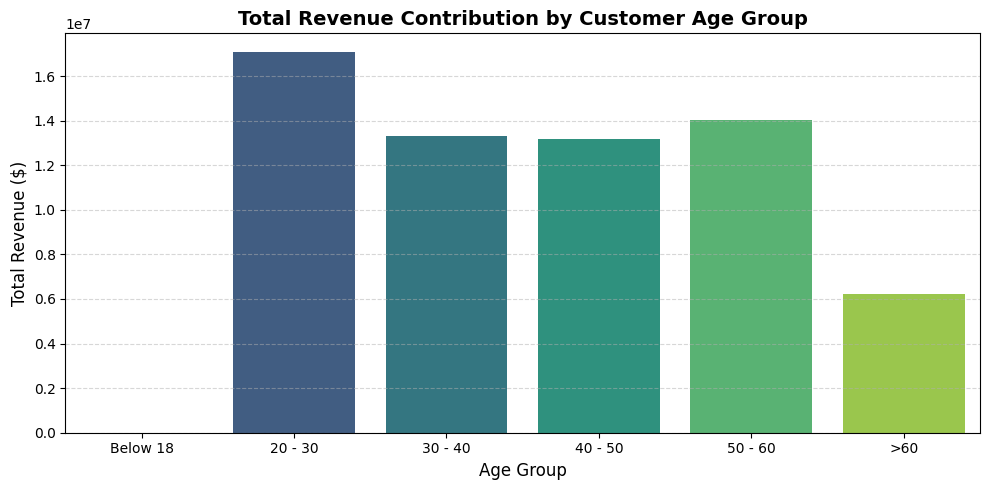

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group the merged customer demographics and financials by Age Group and calculate total revenue
age_group_revenue = customer_demographics_df.groupby('Age_Group', observed=False).agg(
    Total_Revenue=('Total_Sales', 'sum'),
    Customer_Count=('customer_id', 'count')
).reset_index()

age_group_revenue['Avg_Revenue_Per_Customer'] = age_group_revenue['Total_Revenue'] / age_group_revenue['Customer_Count']

print("--- REVENUE CONTRIBUTION BY AGE GROUP ---")
display(age_group_revenue.style.format({
    'Total_Revenue': '${:,.2f}',
    'Customer_Count': '{:,}',
    'Avg_Revenue_Per_Customer': '${:,.2f}'
}))

# Visualize total revenue by age group
plt.figure(figsize=(10, 5))
sns.barplot(
    data=age_group_revenue,
    x='Age_Group',
    y='Total_Revenue',
    hue='Age_Group',
    palette='viridis',
    legend=False
)
plt.title('Total Revenue Contribution by Customer Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

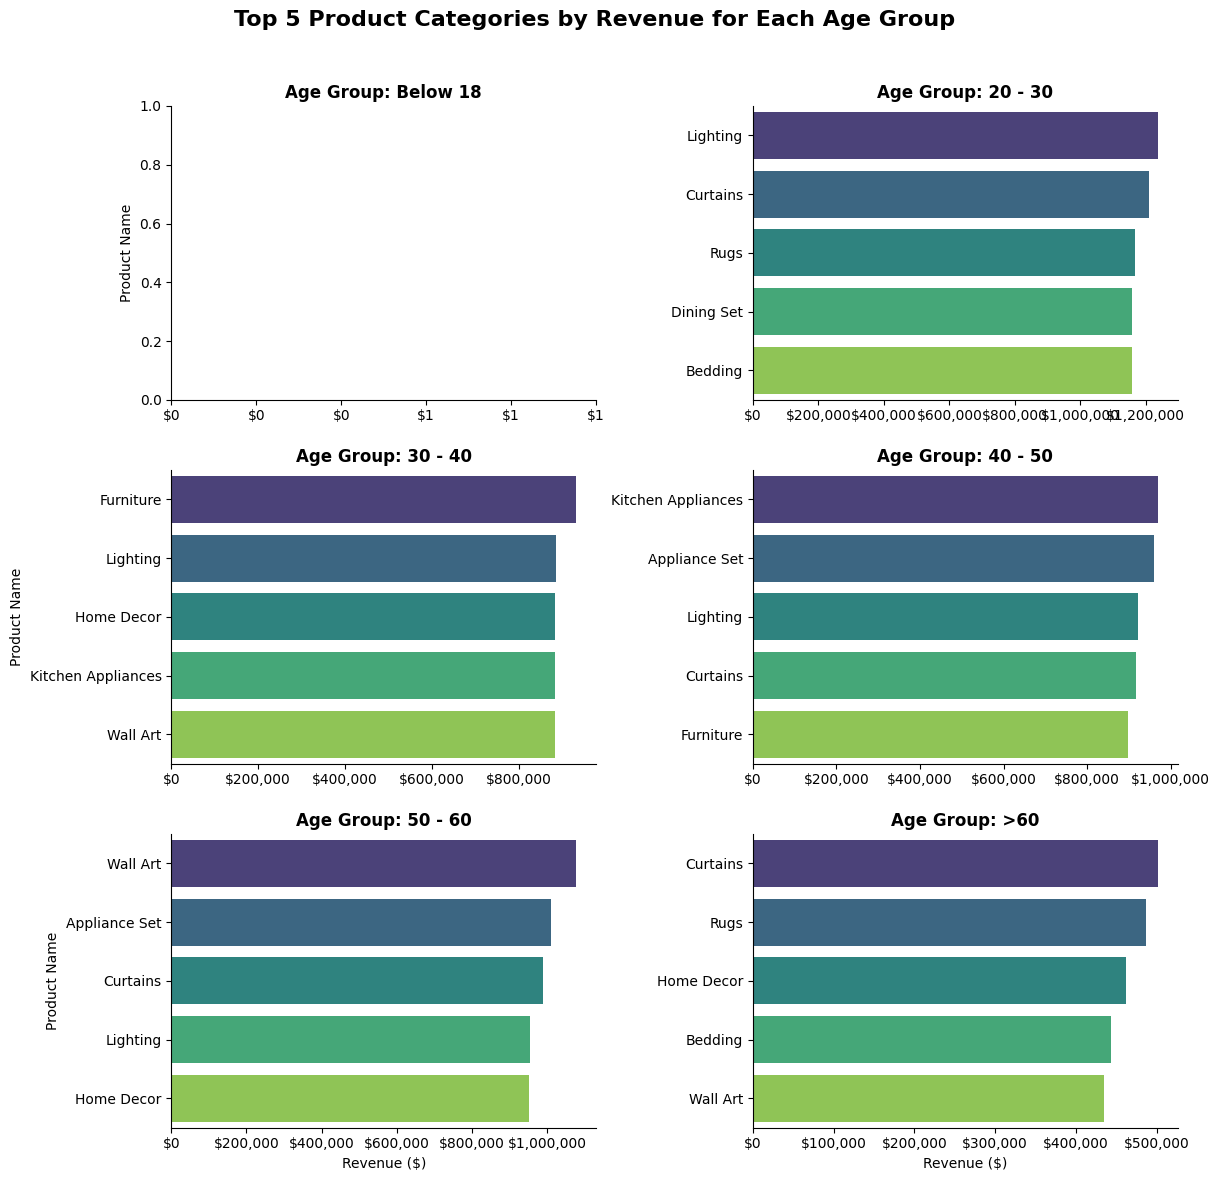

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker

# Ensure datasets are loaded and merged
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)
merged_sales_df = pd.merge(purch_df, cust_df, on='customer_id')

# Define the custom age bins and labels
bins = [-np.inf, 17, 30, 40, 50, 60, np.inf]
labels = ['Below 18', '20 - 30', '30 - 40', '40 - 50', '50 - 60', '>60']
merged_sales_df['Age_Group'] = pd.cut(merged_sales_df['age'], bins=bins, labels=labels)
merged_sales_df['Sales'] = merged_sales_df['price']

# Group and find top 5 products per age group
product_by_age = merged_sales_df.groupby(['Age_Group', 'product_name'], observed=False)['Sales'].sum().reset_index()
top_5_by_age = product_by_age.groupby('Age_Group', observed=False).apply(
    lambda x: x.nlargest(5, 'Sales'), include_groups=False
).reset_index()

# Filter out groups with zero sales (like Below 18)
top_5_by_age_filtered = top_5_by_age[top_5_by_age['Sales'] > 0]

# Plot the data using a faceted grid for clarity
g = sns.FacetGrid(
    top_5_by_age_filtered,
    col="Age_Group",
    col_wrap=2,
    height=4,
    aspect=1.5,
    sharey=False,
    sharex=False
)

g.map_dataframe(
    sns.barplot,
    x="Sales",
    y="product_name",
    hue="product_name",
    palette="viridis",
    legend=False
)

g.set_titles("Age Group: {col_name}", size=12, weight='bold')
g.set_axis_labels("Revenue ($)", "Product Name")

# Clean implementation of formatting ticks using FixedLocator to avoid UserWarnings
for ax in g.axes.flat:
    ticks = ax.get_xticks()
    ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
    ax.set_xticklabels([f'${x:,.0f}' for x in ticks])

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Top 5 Product Categories by Revenue for Each Age Group", size=16, weight='bold')
plt.show()

**Age Distribution Across Customer Value Segments**

The 20–30 age group is the strongest revenue contributor, generating approximately $17 million, while customers aged 30–60 continue to provide a stable revenue base. Revenue declines significantly among customers above 60. Importantly, each age group shows different demand for top products, highlighting an opportunity to tailor product offerings and marketing strategies to specific age segments.

In [ ]:
import pandas as pd

# Ensure we have the merged customer demographics and financials dataset
# total spending per customer is 'Total_Sales' in our customer_demographics_df
correlation_value = customer_demographics_df['age'].corr(customer_demographics_df['Total_Sales'])

print(f"Correlation between Customer Age and Total Spend: {correlation_value:.4f}")

Correlation between Customer Age and Total Spend: 0.0518


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Prepare features (X) and target variable (y)
# We use 'income' and 'age' from customer_demographics_df to predict 'Total_Sales'
X = customer_demographics_df[['income', 'age']]
y = customer_demographics_df['Total_Sales']

# 2. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Fit the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Model Predictions and Evaluation
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

# 5. Output Results
print("--- REGRESSION MODEL COEFFICIENTS ---")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Income Coefficient: {model.coef_[0]:.4f} (Change in spend per $1 increase in income)")
print(f"Age Coefficient: {model.coef_[1]:.4f} (Change in spend per 1 year increase in age)")
print("\n--- MODEL EVALUATION ---")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")

--- REGRESSION MODEL COEFFICIENTS ---
Intercept: 61814.66
Income Coefficient: 0.0057 (Change in spend per $1 increase in income)
Age Coefficient: 37.6093 (Change in spend per 1 year increase in age)

--- MODEL EVALUATION ---
R-squared (R2) Score: -0.0049
Mean Absolute Error (MAE): $7,051.03


Objective 5:
Temporal Sales Trends and Demand Seasonality

Examine periodic and monthly variations in sales transactions over time (Date) to detect peak purchasing windows and seasonal demand fluctuations.

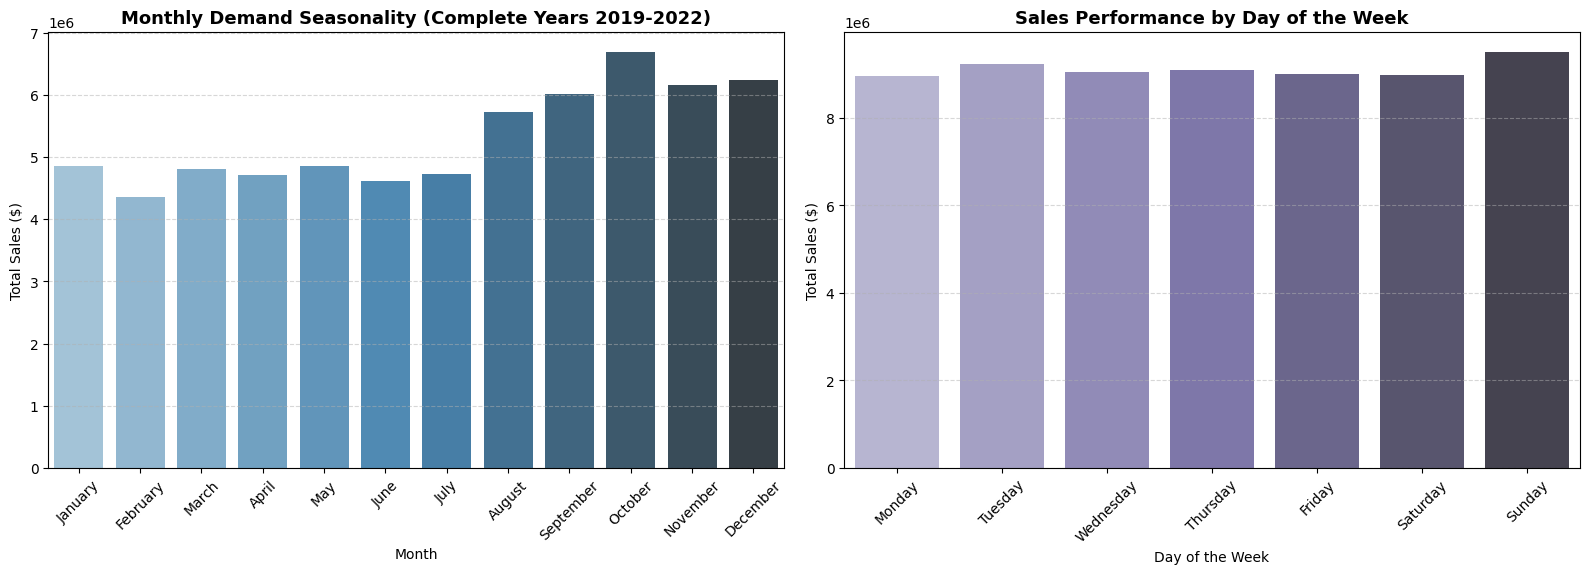

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare temporal data
# We will use df (the purchase dataset) which already has 'order_date' as datetime
df_time = df.copy()
df_time['Year'] = df_time['order_date'].dt.year
df_time['Month'] = df_time['order_date'].dt.to_period('M')
df_time['Month_Name'] = df_time['order_date'].dt.strftime('%B')
df_time['Day_of_Week'] = df_time['order_date'].dt.strftime('%A')

# Define Revenue rule (Sales = Price)
df_time['Sales'] = df_time['price']

# 2. Filter out incomplete months if any
# As noted before, Jan 2023 only contains partial records (up to Jan 16), so we exclude it for true seasonality representation
completed_df = df_time[df_time['order_date'] < '2023-01-01']

# 3. Aggregate Sales by Month Name (Seasonality over completed years)
monthly_seasonality = completed_df.groupby('Month_Name').agg(
    Total_Sales=('Sales', 'sum'),
    Order_Count=('order_id', 'count')
).reindex([
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]).reset_index()

# 4. Aggregate Sales by Day of the Week
weekly_pattern = df_time.groupby('Day_of_Week').agg(
    Total_Sales=('Sales', 'sum'),
    Order_Count=('order_id', 'count')
).reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
]).reset_index()

# 5. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Monthly Seasonality (Total Sales over complete years)
sns.barplot(
    data=monthly_seasonality,
    x='Month_Name',
    y='Total_Sales',
    ax=axes[0],
    palette='Blues_d',
    hue='Month_Name',
    legend=False
)
axes[0].set_title('Monthly Demand Seasonality (Complete Years 2019-2022)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Total Sales ($)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, axis='y', linestyle='--', alpha=0.5)

# Plot 2: Day of the Week Performance
sns.barplot(
    data=weekly_pattern,
    x='Day_of_Week',
    y='Total_Sales',
    ax=axes[1],
    palette='Purples_d',
    hue='Day_of_Week',
    legend=False
)
axes[1].set_title('Sales Performance by Day of the Week', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Day of the Week')
axes[1].set_ylabel('Total Sales ($)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Temporal Sales Trends and Demand Seasonality Analysis**

The Monthly Demand Seasonality chart shows that sales remain relatively stable from January to July, ranging between approximately $4.3million and  $4.9 million. A noticeable upward trend begins in August, with sales increasing steadily and reaching a peak of approximately $6.7 million in October. Although sales decline slightly in November and December, they remain significantly higher than the first half of the year. This suggests stronger customer demand in the third and fourth quarters, likely driven by seasonal shopping patterns and year-end promotional activities.

The Sales Performance by Day of the Week chart indicates that revenue is distributed quite evenly throughout the week, suggesting consistent purchasing behaviour. However, Sunday records the highest sales, while Monday, Friday, and Saturday are slightly lower. The small variation between days suggests that customer demand is not heavily concentrated on a specific day, although weekends appear to provide a slight boost in sales. Based on this trend, the company should focus inventory planning and marketing campaigns during August to December, while leveraging weekend promotions to maximise sales opportunities.

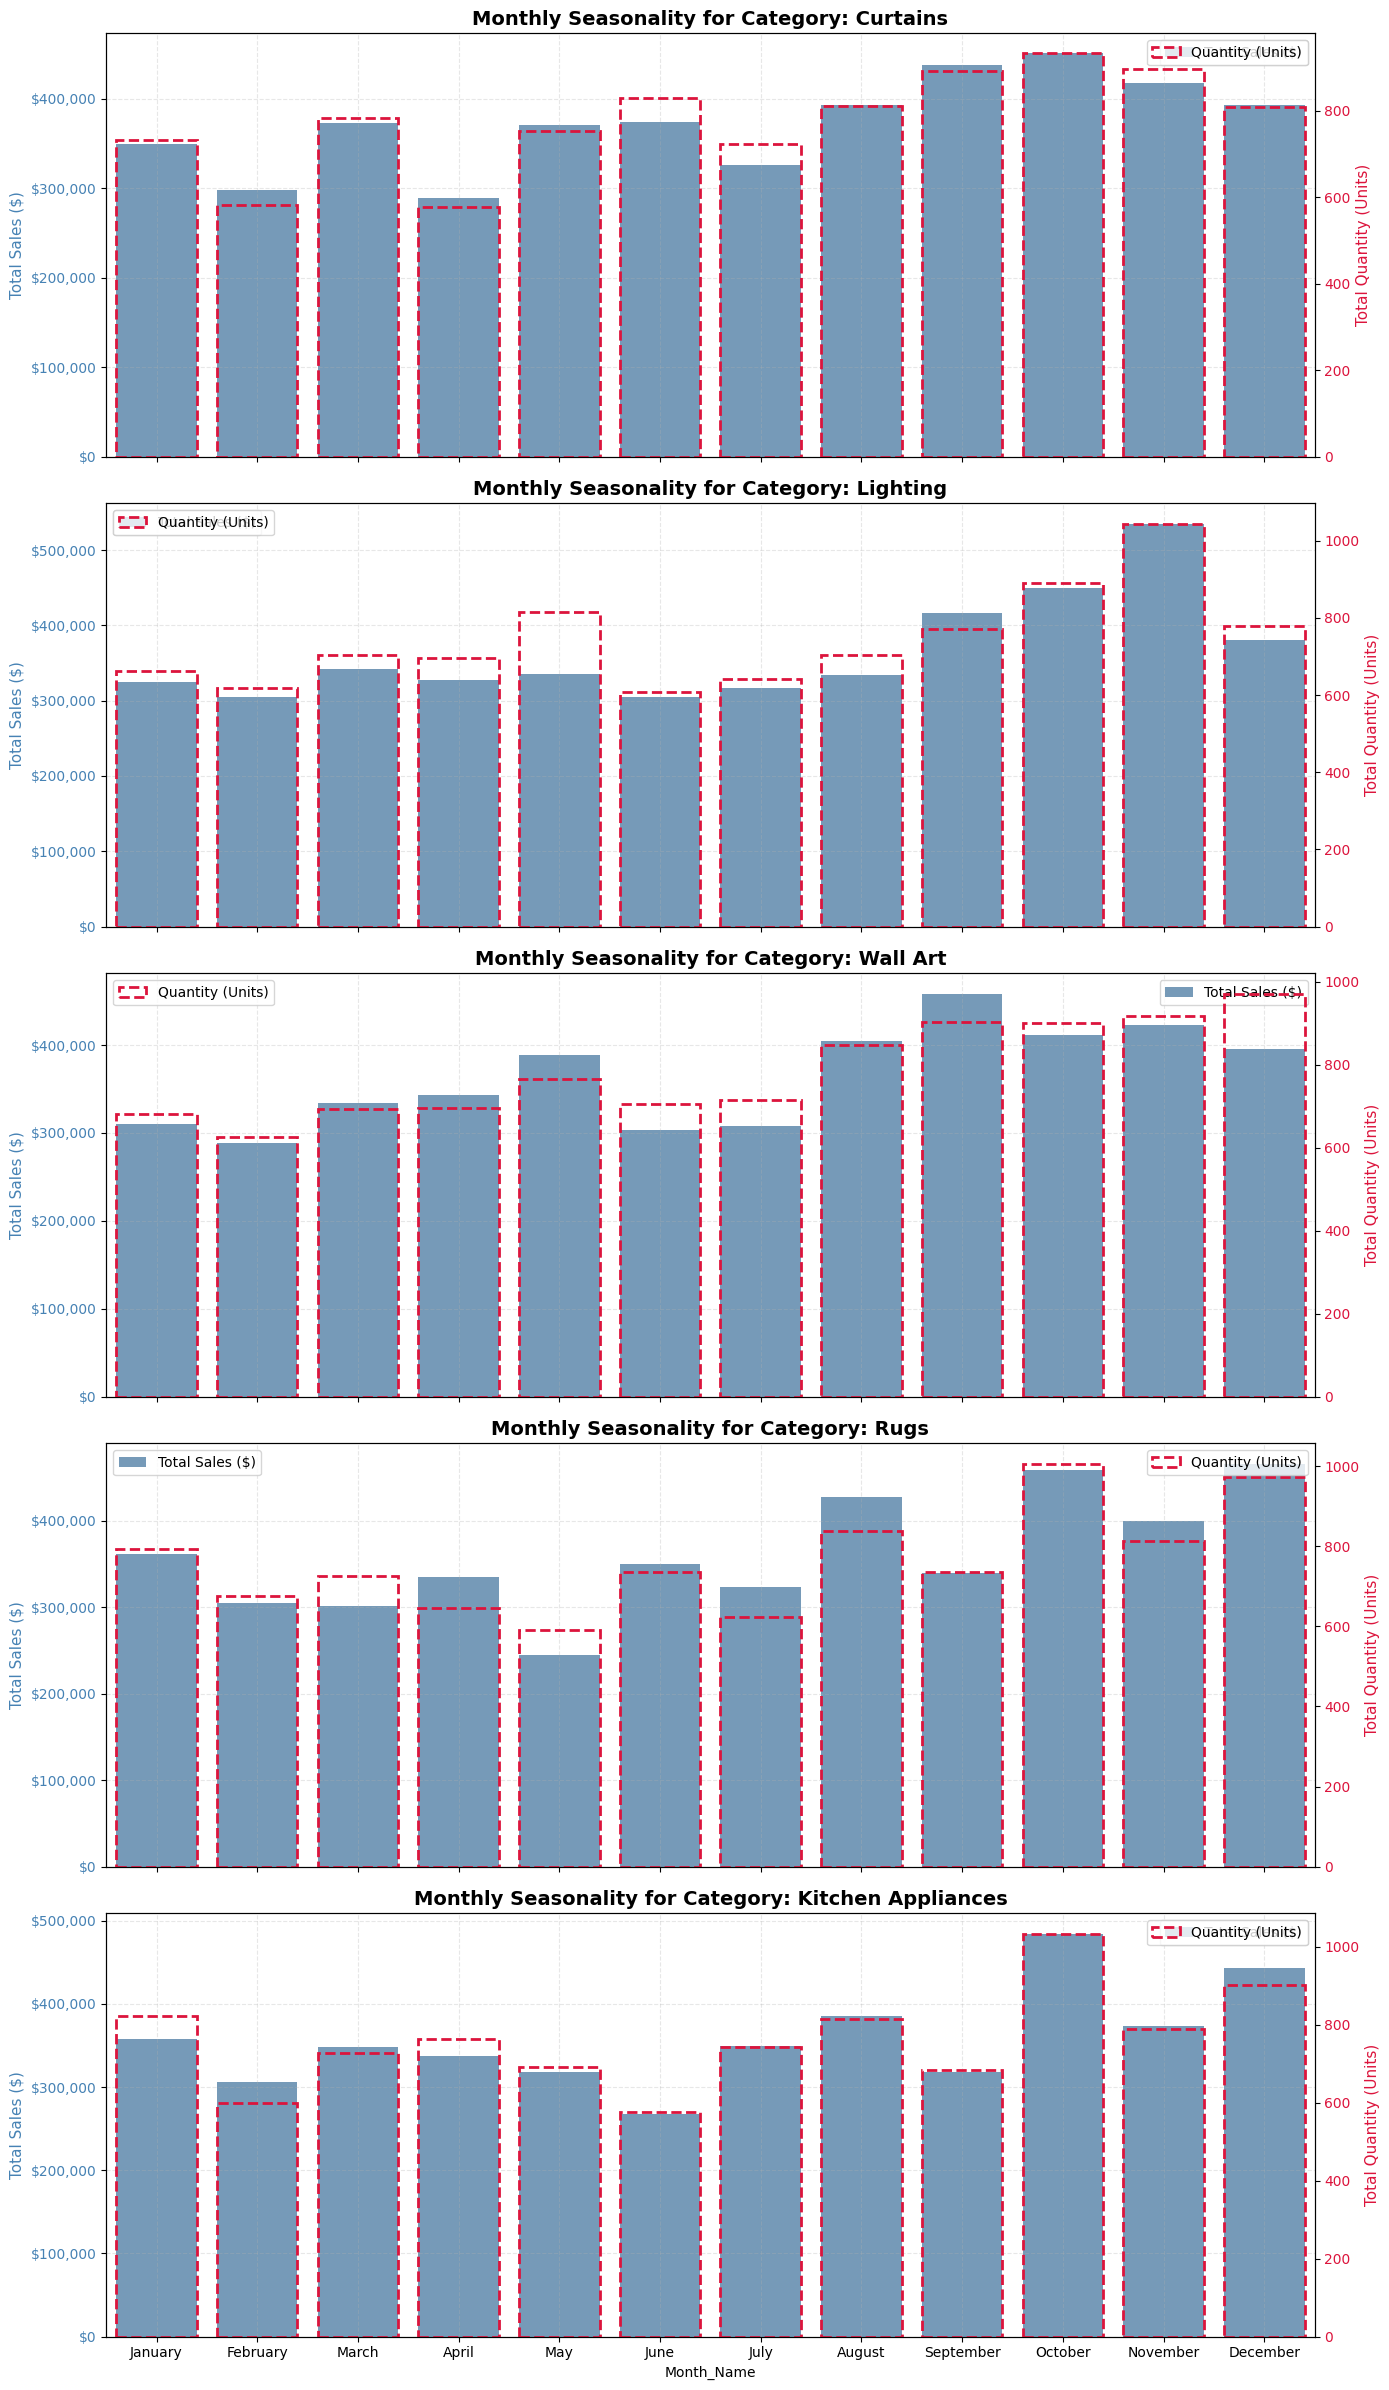

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df_all = pd.read_csv(purch_url)

# 2. Parse dates and filter out incomplete Jan 2023 records
df_all['order_date'] = pd.to_datetime(df_all['order_date'], format='%d-%m-%Y')
df_completed = df_all[df_all['order_date'] < '2023-01-01'].copy()

# Define sales based on user definition (sales = price)
df_completed['Sales'] = df_completed['price']
df_completed['Month_Name'] = df_completed['order_date'].dt.strftime('%B')

# Order of months for chronological seasonality
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

# 3. Get top 5 product categories by total sales
top_5_products = df_completed.groupby('product_name')['Sales'].sum().nlargest(5).index.tolist()

# 4. Group data by product and month
seasonal_data = df_completed[df_completed['product_name'].isin(top_5_products)].groupby(
    ['product_name', 'Month_Name']
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Quantity=('quantity', 'sum')
).reset_index()

# 5. Create 5 different bar charts in a vertical layout
fig, axes = plt.subplots(5, 1, figsize=(14, 24), sharex=True)

for idx, product in enumerate(top_5_products):
    prod_df = seasonal_data[seasonal_data['product_name'] == product].copy()
    # Ensure chronological order of months
    prod_df['Month_Name'] = pd.Categorical(prod_df['Month_Name'], categories=month_order, ordered=True)
    prod_df = prod_df.sort_values('Month_Name')

    ax1 = axes[idx]

    # Plot Total Sales (Revenue) on primary Y-axis as Blue Bars
    sns.barplot(
        data=prod_df,
        x='Month_Name',
        y='Total_Sales',
        ax=ax1,
        color='steelblue',
        alpha=0.8,
        label='Total Sales ($)'
    )
    ax1.set_title(f'Monthly Seasonality for Category: {product}', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Total Sales ($)', color='steelblue', fontsize=11)
    ax1.tick_params(axis='y', labelcolor='steelblue')

    # Format primary Y-axis with dollar formatting
    ax1.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: f"${x:,.0f}"))

    # Create a secondary Y-axis for Total Quantity (Units) as Red line with bars or overlay
    ax2 = ax1.twinx()
    sns.barplot(
        data=prod_df,
        x='Month_Name',
        y='Total_Quantity',
        ax=ax2,
        facecolor='none',
        edgecolor='crimson',
        linewidth=2,
        linestyle='--',
        label='Quantity (Units)'
    )
    ax2.set_ylabel('Total Quantity (Units)', color='crimson', fontsize=11)
    ax2.tick_params(axis='y', labelcolor='crimson')

    ax1.grid(True, linestyle='--', alpha=0.3)

plt.xlabel('Month', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Ensure we have the base purchase and customer data merged
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

purch_df['order_date'] = pd.to_datetime(purch_df['order_date'], format='%d-%m-%Y')
# Filter out incomplete 2023 data
df_comp = purch_df[purch_df['order_date'] < '2023-01-01'].copy()
df_comp['Sales'] = df_comp['price']
df_comp['Month_Name'] = df_comp['order_date'].dt.strftime('%B')

# Merge with demographics
merged_full = pd.merge(df_comp, cust_df, on='customer_id')

# Split into October vs. Other Months
october_data = merged_full[merged_full['Month_Name'] == 'October']
other_months_data = merged_full[merged_full['Month_Name'] != 'October']

print("=== 1. DISCOUNT ANALYSIS ===")
avg_discount_oct = october_data['discount'].mean()
avg_discount_others = other_months_data['discount'].mean()
print(f"Average Discount in October: {avg_discount_oct:.2%}")
print(f"Average Discount in Other Months: {avg_discount_others:.2%}")

print("\n=== 2. REGIONAL / COUNTRY SHARE IN OCTOBER ===")
oct_country_sales = october_data.groupby('country')['Sales'].sum().sort_values(ascending=False).reset_index()
oct_country_sales['Share_Percent'] = (oct_country_sales['Sales'] / october_data['Sales'].sum()) * 100
display(oct_country_sales.style.format({'Sales': '${:,.2f}', 'Share_Percent': '{:.2f}%'}))

print("\n=== 3. PRODUCT SALES SHIFTS IN OCTOBER ===")
# Compare product sales in October to average monthly sales in other months
product_oct_sales = october_data.groupby('product_name')['Sales'].sum().reset_index().rename(columns={'Sales': 'October_Sales'})
product_other_sales = other_months_data.groupby('product_name')['Sales'].sum().reset_index().rename(columns={'Sales': 'Other_Months_Total'})

product_comparison = pd.merge(product_oct_sales, product_other_sales, on='product_name')
# Since there are 11 other months, the average sales per month in 'Other' is total / 11
product_comparison['Avg_Monthly_Sales_Others'] = product_comparison['Other_Months_Total'] / 11
product_comparison['Sales_Increase_Amount'] = product_comparison['October_Sales'] - product_comparison['Avg_Monthly_Sales_Others']
product_comparison['Pct_Increase'] = (product_comparison['Sales_Increase_Amount'] / product_comparison['Avg_Monthly_Sales_Others']) * 100

top_shifts = product_comparison.sort_values(by='Sales_Increase_Amount', ascending=False).head(5)
display(top_shifts.style.format({
    'October_Sales': '${:,.2f}',
    'Avg_Monthly_Sales_Others': '${:,.2f}',
    'Sales_Increase_Amount': '${:,.2f}',
    'Pct_Increase': '{:.2f}%'
}))

=== 1. DISCOUNT ANALYSIS ===
Average Discount in October: 24.76%
Average Discount in Other Months: 24.93%

=== 2. REGIONAL / COUNTRY SHARE IN OCTOBER ===


,country,Sales,Share_Percent
0,Chile,"$1,828,628.63",27.37%
1,Colombia,"$1,816,453.28",27.18%
2,Mexico,"$1,523,094.97",22.79%
3,Brazil,"$1,513,997.56",22.66%



=== 3. PRODUCT SALES SHIFTS IN OCTOBER ===


,product_name,October_Sales,Other_Months_Total,Avg_Monthly_Sales_Others,Sales_Increase_Amount,Pct_Increase
2,Bedding,"$511,842.44",3645738.400000,"$331,430.76","$180,411.68",54.43%
1,Appliance Set,"$509,886.70",3724965.730000,"$338,633.25","$171,253.45",50.57%
14,Kitchen Appliances,"$484,460.09",3805297.640000,"$345,936.15","$138,523.94",40.04%
8,Furniture,"$473,861.81",3773221.530000,"$343,020.14","$130,841.67",38.14%
5,Dining Set,"$457,039.62",3697428.490000,"$336,129.86","$120,909.76",35.97%


As October is the peak of the year, further analyse following factor:
i. Discount: Promotion discount rate in October seem to be identical, justify that the peak is not triggered by a sudden promotion event or huge store-wide discount rate.

ii. Geographically balance: There is no high demand derrive isolated from a single country, justify that this is not cuased by holiday or a specific local event.

iii. Product: Product specification in October had switch to Bedding, Appliance Set, Kietchen Appliance and Dining Set which is different as compare to Top 5 yearly products (Curtains, Lighting Wall Art & Rugs). As such, the peak may be triggle by the consumer buying bahavious toward home upgrading for the early preparation of year end holiday.

In [ ]:
# use linear regression to do predictive analysis for sales
# Split into training and testing sets (e.g., 80% train, 20% test) X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**12 Months Sales Forecast **

Based on the available data, using 80% training and 20% testing split chronological for the forecast.

In [14]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Load datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# 2. Process dates and calculate Sales
purch_df['order_date'] = pd.to_datetime(purch_df['order_date'], format='%d-%m-%Y')
purch_df['Sales'] = purch_df['price']

# Exclude the final incomplete month (Jan 2023) to ensure forecast quality
complete_df = purch_df[purch_df['order_date'] < '2023-01-01'].copy()

# 3. Chronological monthly aggregation
monthly_data = complete_df.resample('ME', on='order_date')['Sales'].sum().reset_index()
monthly_data = monthly_data.sort_values('order_date').reset_index(drop=True)
monthly_data['Month_Index'] = np.arange(len(monthly_data)) + 1

# 4. Chronological 80/20 split (not random, preserving temporal order)
split_idx = int(len(monthly_data) * 0.8)
train_set = monthly_data.iloc[:split_idx].copy()
test_set = monthly_data.iloc[split_idx:].copy()

# Summarize splits
print("=== CHRONOLOGICAL DATASETS SUMMARY ===")
print(f"Training set period: {train_set['order_date'].dt.strftime('%B %Y').iloc[0]} to {train_set['order_date'].dt.strftime('%B %Y').iloc[-1]} ({len(train_set)} months)")
print(f"Training total sales: ${train_set['Sales'].sum():,.2f}")
print(f"Testing set period: {test_set['order_date'].dt.strftime('%B %Y').iloc[0]} to {test_set['order_date'].dt.strftime('%B %Y').iloc[-1]} ({len(test_set)} months)")
print(f"Testing total sales: ${test_set['Sales'].sum():,.2f}\n")

# 5. Fit model on Training Set
X_train = train_set[['Month_Index']]
y_train = train_set['Sales']
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Forecast next 12 months
max_index = monthly_data['Month_Index'].max()
future_indices = np.arange(max_index + 1, max_index + 13)
X_future = pd.DataFrame({'Month_Index': future_indices})

forecast_sales = model.predict(X_future)
last_date = monthly_data['order_date'].max()
future_dates = pd.date_range(start=last_date + pd.offsets.MonthEnd(1), periods=12, freq='ME')

forecast_df = pd.DataFrame({
    'order_date': future_dates,
    'Predicted_Sales': forecast_sales
})

print("=== 12-MONTH SALES FORECAST ===")
display(forecast_df.style.format({
    'order_date': lambda x: x.strftime('%B %Y'),
    'Predicted_Sales': '${:,.2f}'
}))

=== CHRONOLOGICAL DATASETS SUMMARY ===
Training set period: August 2019 to March 2022 (32 months)
Training total sales: $49,652,197.11
Testing set period: April 2022 to December 2022 (9 months)
Testing total sales: $14,079,733.20

=== 12-MONTH SALES FORECAST ===


,order_date,Predicted_Sales
0,January 2023,"$1,575,003.63"
1,February 2023,"$1,575,920.19"
2,March 2023,"$1,576,836.76"
3,April 2023,"$1,577,753.33"
4,May 2023,"$1,578,669.90"
5,June 2023,"$1,579,586.46"
6,July 2023,"$1,580,503.03"
7,August 2023,"$1,581,419.60"
8,September 2023,"$1,582,336.17"
9,October 2023,"$1,583,252.73"


**12 months forecast in different segments:**

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# 1. Load the datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# 2. Merge and set up sales and age categories
purch_df['order_date'] = pd.to_datetime(purch_df['order_date'], format='%d-%m-%Y')
purch_df['Sales'] = purch_df['price']

# Filter out incomplete month (Jan 2023)
complete_df = purch_df[purch_df['order_date'] < '2023-01-01'].copy()
merged_df = pd.merge(complete_df, cust_df, on='customer_id')

# Bin ages based on user request (below 18, 20-30, 30-40, 40-50, 50-60, >60)
age_bins = [-np.inf, 18, 30, 40, 50, 60, np.inf]
age_labels = ['Below 18', '20-30', '30-40', '40-50', '50-60', '>60']
merged_df['Age_Group'] = pd.cut(merged_df['age'], bins=age_bins, labels=age_labels, right=False)

# 3. Aggregate Sales into defined Segment combinations
segment_df = merged_df.groupby(['Age_Group', 'country', 'gender', 'product_name'], observed=False)['Sales'].sum().reset_index()

# 4. Feature Engineering: One-hot encode categoricals
encoded_df = pd.get_dummies(segment_df, columns=['Age_Group', 'country', 'gender', 'product_name'], drop_first=True)

X = encoded_df.drop(columns=['Sales'])
y = encoded_df['Sales']

# 5. Split and Train Multi-linear regression model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_test = multi_model.predict(X_test)

# 6. Check Model Performance Metrics
r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = root_mean_squared_error(y_test, y_pred_test)

print("=== ACCURACY MATRIX: MULTI-SEGMENTED REGRESSION MODEL ===")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}\n")

# 7. Retain original forecasts in main dataset and show predictions
segment_df['Predicted_Sales_Multi'] = multi_model.predict(X)

print("--- MULTI-DIMENSIONAL DEMOGRAPHIC SEGMENT FORECAST SAMPLES ---")
display(segment_df.head(15).style.format({
    'Sales': '${:,.2f}',
    'Predicted_Sales_Multi': '${:,.2f}'
}))

=== ACCURACY MATRIX: MULTI-SEGMENTED REGRESSION MODEL ===
R-squared (R2) Score: 0.7663
Mean Absolute Error (MAE): $17,186.12
Root Mean Squared Error (RMSE): $23,499.03

--- MULTI-DIMENSIONAL DEMOGRAPHIC SEGMENT FORECAST SAMPLES ---


,Age_Group,country,gender,product_name,Sales,Predicted_Sales_Multi
0,Below 18,Brazil,Female,Activewear Set,$0.00,"$-40,426.07"
1,Below 18,Brazil,Female,Appliance Set,$0.00,"$37,791.34"
2,Below 18,Brazil,Female,Bedding,$0.00,"$38,965.26"
3,Below 18,Brazil,Female,Camera,$0.00,"$-9,946.58"
4,Below 18,Brazil,Female,Curtains,$0.00,"$41,892.49"
5,Below 18,Brazil,Female,Dining Set,$0.00,"$38,953.07"
6,Below 18,Brazil,Female,Dress,$0.00,"$-42,272.39"
7,Below 18,Brazil,Female,Formal Shirt,$0.00,"$-40,001.18"
8,Below 18,Brazil,Female,Furniture,$0.00,"$37,351.92"
9,Below 18,Brazil,Female,Gaming Console,$0.00,"$-9,287.84"


By using multi-dimentional segmental linear regression model:
1. R-squared ($R^2$$R^2$) Score: 0.7663 (76.63%)
This shows that the segment features (Age Group, Country, Gender, and Product Category) explain 76.63% of the variance in customer spend, demonstrating a high level of predictive power compared to the simple chronological time-series model.

2. Mean Absolute Error (MAE): $17,186.12
On average, the predicted segment sales deviate from the actual values by $17,186.12.

3. Root Mean Squared Error (RMSE): $23,499.03
The standard deviation of residuals shows how tightly grouped our segment predictions are to historical patterns.